# ==========================================================
# MÔ HÌNH DỰ BÁO RỦI RO TÍN DỤNG CÁ NHÂN - NOVA BANK
# Phân tích, Huấn luyện và Đánh giá Mô hình (Final Version)
# ==========================================================

**MỤC TIÊU DỰ ÁN:** 
Xây dựng một mô hình máy học mạnh mẽ để đánh giá xác suất vỡ nợ (Probability of Default - PD) của khách hàng dựa trên lịch sử tín dụng, đặc điểm khoản vay và các thông tin định danh hợp lệ.

**CÁC ĐIỂM CẢI TIẾN TRỌNG TÂM:**
1. **Chống rò rỉ dữ liệu (Data Leakage):** Loại bỏ hoàn toàn biến `loan_grade` (vốn dĩ đã là nhãn nội bộ của ngân hàng) và sử dụng cơ chế chia 3 tập `Train / Validation / Test` để đánh giá trung thực nhất.
2. **Tuân thủ pháp luật (Compliance):** Loại bỏ biến `gender` và `marital_status` nhằm đáp ứng Đạo luật Bình đẳng Cơ hội Tín dụng (ECOA).
3. **Tối ưu hóa Nghiệp vụ (Business Optimization):** Việc chọn ngưỡng (Cut-off Threshold) không chỉ dựa trên chỉ số kỹ thuật (F1-Score) mà được điều chỉnh theo **Ma trận chi phí kinh doanh (Cost Matrix)**, ưu tiên giảm thiểu thiệt hại từ nợ xấu.
4. **Minh bạch hóa Quyết định (Explainability):** Ứng dụng thuật toán SHAP để giải thích lý do mô hình từ chối hoặc chấp thuận một khoản vay.

**LƯU Ý & GIỚI HẠN (LIMITATIONS):**
* Dữ liệu sử dụng mang tính chất minh họa tổng hợp.
* Các biến `person_home_ownership`, `employment_type` được giữ lại do mang tín hiệu tài chính mạnh. Tuy nhiên, khi vận hành thực tế (Production), ngân hàng cần theo dõi các chỉ số công bằng (Fairness/Disparate Impact) định kỳ vì chúng có thể vô tình đóng vai trò là biến đại diện (proxy) cho các nhóm yếu tố kinh tế - xã hội.

In [2]:
# 1. IMPORT THƯ VIỆN CẦN THIẾT
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap # Thư viện giải thích mô hình (Explainable AI)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score, classification_report, confusion_matrix, 
    precision_recall_curve, PrecisionRecallDisplay, RocCurveDisplay
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Cấu hình hiển thị biểu đồ của thư viện SHAP trên Jupyter
shap.initjs()

### 2. KHỞI TẠO CÁC HÀM XỬ LÝ (CUSTOM CLASSES & FUNCTIONS)
*   **Winsorizer:** Bộ lọc gọt giũa các giá trị ngoại lai (outliers) ở phân vị 1% và 99%. Sử dụng `np.nanquantile` để không bị lỗi khi gặp dữ liệu khuyết thiếu.
*   **calculate_business_cost:** Hàm tính toán chi phí thiệt hại của mô hình. Trong tín dụng, việc duyệt nhầm cho khách hàng xấu (False Negative) thường gây thiệt hại về vốn nặng nề hơn việc từ chối nhầm một khách hàng tốt (False Positive). Chúng ta giả định tỷ lệ thiệt hại là **FN : FP = 5 : 1**.

In [3]:
# Lớp tùy chỉnh cắt ngoại lai (Winsorizing)
class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile
        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        for col in X_df.columns:
            # Dùng nanquantile để bỏ qua giá trị NaN khi tính toán ngưỡng
            self.lower_bounds_[col] = np.nanquantile(X_df[col], self.lower_quantile)
            self.upper_bounds_[col] = np.nanquantile(X_df[col], self.upper_quantile)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for col in X_df.columns:
            X_df[col] = np.clip(X_df[col], self.lower_bounds_[col], self.upper_bounds_[col])
        return X_df.values

    # Bắt buộc khai báo để Pipeline trích xuất được tên Feature cho Feature Importance & SHAP
    def get_feature_names_out(self, input_features=None):
        return input_features

# Hàm tính toán chi phí tài chính dựa trên ngưỡng cắt (Threshold)
def calculate_business_cost(y_true, y_prob, threshold, cost_fn=5, cost_fp=1):
    """
    Giả định: Tổn thất khi duyệt nhầm khách vỡ nợ (FN) tốn gấp 5 lần tổn thất cơ hội khi mất khách tốt (FP)
    """
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    total_cost = (fn * cost_fn) + (fp * cost_fp)
    return total_cost

### 3. TẢI DỮ LIỆU & XỬ LÝ LỖI LOGIC NHẬP LIỆU (DATA ENTRY BUGS)
Lọc các sai sót trong quá trình nhập liệu trước khi đưa vào Imputer:
1.  Tuổi > 100
2.  Số năm kinh nghiệm > 60
3.  Tuổi đi làm < 14 tuổi (Điều chỉnh quy tắc từ 18 xuống 14 để tránh xóa nhầm quá nhiều hồ sơ của nhóm lao động sớm).

In [4]:
# Sử dụng đường dẫn tương đối để dễ dàng di chuyển thư mục dự án
file_path = r"C:\Users\admin\Documents\Đề án 2026 kì hè\risk credit analytics\Credit Risk Dataset.xlsx"
df = pd.read_excel(file_path, sheet_name="Credit Risk Data")

print(f"Kích thước bộ dữ liệu thô ban đầu: {df.shape}")

# Chuyển các giá trị vi phạm logic thành NaN để Imputer xử lý nội suy sau
df.loc[df["person_age"] > 100, "person_age"] = np.nan
df.loc[df["person_emp_length"] > 60, "person_emp_length"] = np.nan

# Khách hàng không thể có số năm kinh nghiệm lớn hơn (Tuổi hiện tại - 14)
invalid_emp = df["person_emp_length"] > (df["person_age"] - 14)
df.loc[invalid_emp, "person_emp_length"] = np.nan

print(f"Đã xử lý và gán NaN cho {invalid_emp.sum()} dòng vi phạm logic về tuổi lao động.")

Kích thước bộ dữ liệu thô ban đầu: (32581, 29)
Đã xử lý và gán NaN cho 0 dòng vi phạm logic về tuổi lao động.


### 4. LỰA CHỌN ĐẶC TRƯNG & KIỂM TRA ĐA CỘNG TUYẾN (VIF)
Thực hiện loại bỏ các biến không mang giá trị, các biến gây rò rỉ rủi ro (Leakage) và nhóm biến bị cấm bởi các quy định pháp luật. Sau đó, tính toán Hệ số phóng đại phương sai (VIF) để chứng minh hiện tượng Đa cộng tuyến (Multicollinearity) đã được giải quyết.

In [5]:
drop_cols = [
    # 1. Biến định danh không mang giá trị phân loại
    "client_ID", "country", "state", "city", "city_latitude", "city_longitude",
    # 2. Biến rò rỉ nhãn (Data Leakage)
    "loan_grade", 
    # 3. Đa cộng tuyến (Xử lý VIF cao)
    "loan_percent_income", 
    "cb_person_cred_hist_length", 
    "debt_to_income_ratio", 
    # 4. Rủi ro tuân thủ pháp luật (ECOA / Fairness)
    "gender", "marital_status"
]

df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)

X = df.drop("loan_status", axis=1)
y = df["loan_status"]

numerical_features = X.select_dtypes(exclude=["object"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

# Điền khuyết tạm thời để tính VIF
imputer_vif = SimpleImputer(strategy="median")
X_num_vif = pd.DataFrame(imputer_vif.fit_transform(X[numerical_features]), columns=numerical_features)
vif_df = pd.DataFrame({
    "Variable": X_num_vif.columns,
    "VIF": [variance_inflation_factor(X_num_vif.values, i) for i in range(X_num_vif.shape[1])]
}).sort_values(by="VIF", ascending=False)

print("=== KIỂM TRA HỆ SỐ PHÓNG ĐẠI PHƯƠNG SAI (VIF) TRƯỚC KHI TRAINING ===")
print(vif_df.to_string(index=False))
# Nếu mức VIF lớn nhất < 15, mô hình đã giảm thiểu thành công sự tương quan nội bộ.

=== KIỂM TRA HỆ SỐ PHÓNG ĐẠI PHƯƠNG SAI (VIF) TRƯỚC KHI TRAINING ===
                Variable       VIF
              person_age 14.169756
           person_income 11.361414
           loan_int_rate 10.903196
              other_debt  8.389621
    loan_to_income_ratio  7.016072
               loan_amnt  6.963262
        loan_term_months  6.019793
credit_utilization_ratio  4.358027
           open_accounts  4.131050
       person_emp_length  2.570632
      past_delinquencies  1.486918


### 5. CHIA 3 TẬP DỮ LIỆU & THIẾT LẬP PIPELINE
Để đánh giá mô hình khách quan nhất, ngăn ngừa hiện tượng "vừa học vừa thi", chúng ta sử dụng chiến lược chia 3 tập:
*   **Tập Train (70%):** Dùng để huấn luyện mô hình.
*   **Tập Validation (15%):** Dùng để tìm ngưỡng (Cut-off Threshold) tối ưu.
*   **Tập Test (15%):** Đóng kín hoàn toàn, chỉ dùng duy nhất 1 lần ở cuối dự án để báo cáo sai số thực tế.

In [6]:
# Tách 30% tổng số ra làm tập Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
# Cưa đôi tập Temporary thành 15% Validation và 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"Số lượng tập Train (Huấn luyện): {X_train.shape[0]} dòng")
print(f"Số lượng tập Validation (Định cỡ Threshold): {X_val.shape[0]} dòng")
print(f"Số lượng tập Test (Báo cáo cuối cùng): {X_test.shape[0]} dòng")

# Xây dựng Pipeline tiền xử lý hoàn chỉnh
numeric_transformer = Pipeline([
    ("winsorizer", Winsorizer(lower_quantile=0.01, upper_quantile=0.99)),
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)), # Lưu lại cờ báo hiệu dữ liệu từng bị khuyết
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

Số lượng tập Train (Huấn luyện): 22806 dòng
Số lượng tập Validation (Định cỡ Threshold): 4887 dòng
Số lượng tập Test (Báo cáo cuối cùng): 4888 dòng


### 6. HUẤN LUYỆN BASELINE VÀ CHỌN ỨNG VIÊN (MODEL SELECTION)
So sánh sức mạnh 3 thuật toán nền tảng qua 5-Fold Cross Validation trên tập Train:
1.  **Logistic Regression:** Dễ giải thích hệ số, chuẩn mực truyền thống của ngân hàng (Scorecard).
2.  **Random Forest:** Mô hình cây quyết định tập hợp, độ ổn định cao.
3.  **XGBoost:** Thuật toán tăng cường Gradient cực kỳ tối ưu về mặt hiệu suất phân loại.

In [7]:
# Xử lý vấn đề mất cân bằng nhóm (Class Imbalance)
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight="balanced", n_jobs=-1),
    "XGBoost": XGBClassifier(scale_pos_weight=scale_weight, random_state=42, eval_metric="logloss", n_jobs=-1)
}

print("=== SO SÁNH HIỆU SUẤT CÁC ỨNG VIÊN BẰNG CROSS-VALIDATION ===")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in base_models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    auc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    print(f"{name:<20} AUC = {auc_scores.mean():.4f} ± {auc_scores.std():.4f}")

=== SO SÁNH HIỆU SUẤT CÁC ỨNG VIÊN BẰNG CROSS-VALIDATION ===
Logistic Regression  AUC = 0.8516 ± 0.0049
Random Forest        AUC = 0.9071 ± 0.0028
XGBoost              AUC = 0.9263 ± 0.0055


### 7. TỐI ƯU HÓA SIÊU THAM SỐ (HYPERPARAMETER TUNING) CHO XGBOOST
Dựa trên kết quả Baseline, XGBoost là thuật toán cho ROC-AUC cao nhất. Ta tiến hành tinh chỉnh tham số chuyên sâu cho ứng viên này thông qua `RandomizedSearchCV`.

In [8]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(scale_pos_weight=scale_weight, random_state=42, eval_metric="logloss"))
])

# MỞ RỘNG KHÔNG GIAN TÌM KIẾM CHỐNG OVERFITTING
param_dist = {
    # 1. Để n_estimators lớn vì đã có Early Stopping lo việc dừng sớm
    'model__n_estimators': [500, 1000], 
    'model__learning_rate': [0.01, 0.05, 0.1],
    
    # 2. Ép cây nông hơn (giảm độ phức tạp của mô hình)
    'model__max_depth': [3, 4, 5], 
    'model__min_child_weight': [3, 5, 7, 10],
    
    # 3. Lấy mẫu ngẫu nhiên để tăng tính tổng quát
    'model__subsample': [0.6, 0.7, 0.8],
    'model__colsample_bytree': [0.6, 0.7, 0.8],
    
    # 4. Tham số Điều chuẩn (Regularization) - VŨ KHÍ CHÍNH
    'model__reg_alpha': [0, 0.1, 1.0, 5.0],    # L1: Khử bớt các biến nhiễu
    'model__reg_lambda': [1.0, 5.0, 10.0, 20.0], # L2: Ngăn chặn trọng số biến quá lớn
    'model__gamma': [0, 0.5, 1.0, 2.0]           # Phạt việc tạo thêm nhánh mới
}

print("Đang tiến hành RandomizedSearchCV với Early Stopping...")

# 1. TIỀN XỬ LÝ DỮ LIỆU VALIDATION (Giữ nguyên)
preprocessor = xgb_pipeline.named_steps['preprocessor']
preprocessor.fit(X_train)
X_val_transformed = preprocessor.transform(X_val)

# 2. SỬA LỖI VERSION XGBOOST Ở ĐÂY
# Đưa early_stopping_rounds trực tiếp vào cấu hình của mô hình trong pipeline
xgb_pipeline.set_params(model__early_stopping_rounds=50)

# 3. KHAI BÁO THAM SỐ FIT (Bây giờ KHÔNG còn early_stopping_rounds ở đây nữa)
fit_params = {
    'model__eval_set': [(X_val_transformed, y_val)],
    'model__verbose': False
}

# 4. CÀI ĐẶT RANDOMIZED SEARCH
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    xgb_pipeline, 
    param_distributions=param_dist, 
    n_iter=20,         
    scoring="roc_auc", 
    cv=3, 
    random_state=42, 
    n_jobs=-1, 
    verbose=1
)

# 5. HUẤN LUYỆN KÈM EARLY STOPPING
random_search.fit(X_train, y_train, **fit_params)

# 6. XUẤT KẾT QUẢ
best_model = random_search.best_estimator_
print(f"\nTham số tốt nhất tìm được: {random_search.best_params_}")

Đang tiến hành RandomizedSearchCV với Early Stopping...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Tham số tốt nhất tìm được: {'model__subsample': 0.8, 'model__reg_lambda': 5.0, 'model__reg_alpha': 0, 'model__n_estimators': 1000, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__gamma': 0, 'model__colsample_bytree': 0.6}


### 8. TÌM NGƯỠNG TỐI ƯU TRÊN TẬP VALIDATION (THRESHOLD CALIBRATION)
Tuyệt đối không dùng tập Test ở bước này. Sử dụng tập Validation để mô phỏng một bài toán tài chính thực tế: Ngân hàng nên chọn Threshold nào để giảm thiểu thiệt hại (Business Cost) thay vì chỉ nhìn vào điểm F1 kỹ thuật?

In [9]:
# Chạy dự báo trên tập Validation
y_prob_val = best_model.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, y_prob_val)

# Chiến lược 1: Tối ưu theo kỹ thuật phân loại (F1-Score)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_f1_idx = np.argmax(f1_scores)
best_threshold_f1 = thresholds[best_f1_idx]

# Chiến lược 2: Tối ưu theo Lợi nhuận / Rủi ro Kinh doanh (Cost Matrix)
# Giả định: Từ chối nhầm tốn 1 đồng, Duyệt nhầm nợ xấu tốn 5 đồng
costs = [calculate_business_cost(y_val, y_prob_val, t, cost_fn=5, cost_fp=1) for t in thresholds]
best_cost_idx = np.argmin(costs)
best_threshold_cost = thresholds[best_cost_idx]

print(f"Ngưỡng giúp tối đa hóa F1-Score kỹ thuật: {best_threshold_f1:.3f}")
print(f"Ngưỡng giúp tối thiểu hóa Chi phí rủi ro: {best_threshold_cost:.3f}")

# Cài đặt Threshold chính thức vào mô hình dựa trên bài toán kinh doanh
FINAL_THRESHOLD = best_threshold_cost

Ngưỡng giúp tối đa hóa F1-Score kỹ thuật: 0.670
Ngưỡng giúp tối thiểu hóa Chi phí rủi ro: 0.404


### 9. BÁO CÁO KẾT QUẢ CUỐI CÙNG LÊN TẬP TEST KÍN (FINAL EVALUATION)
Đây là lần duy nhất tập Test được "nhìn thấy". So sánh AUC giữa tập Train và tập Test để đánh giá khách quan xem mô hình có bị học vẹt (Overfitting) hay không.

In [10]:
print("="*60)
print("BÁO CÁO NGHIỆP VỤ TRÊN TẬP TEST")
print("="*60)

# Dự đoán điểm tín dụng trên tập Test
y_prob_test = best_model.predict_proba(X_test)[:, 1]

# Kiểm tra độ trôi mô hình (Overfitting check)
train_auc = roc_auc_score(y_train, best_model.predict_proba(X_train)[:, 1])
test_auc = roc_auc_score(y_test, y_prob_test)
print(f"Mức độ phân tách (AUC) trên tập Huấn luyện: {train_auc:.4f}")
print(f"Mức độ phân tách (AUC) trên tập Kiểm thử: {test_auc:.4f}\n")

# Báo cáo hiệu năng tại ngưỡng được cấu hình bởi Khối Quản trị Rủi ro
y_pred_test = (y_prob_test >= FINAL_THRESHOLD).astype(int)

print(f"Báo cáo phân loại chi tiết (Áp dụng Ngưỡng rủi ro = {FINAL_THRESHOLD:.3f}):")
print(classification_report(y_test, y_pred_test))

# Lưu trữ lại toàn bộ Pipeline (Data Clean -> Model)
joblib.dump(best_model, "nova_bank_credit_risk_production.pkl")
print("✅ Pipeline mô hình đã được đóng gói và lưu trữ thành công!")

BÁO CÁO NGHIỆP VỤ TRÊN TẬP TEST
Mức độ phân tách (AUC) trên tập Huấn luyện: 0.9807
Mức độ phân tách (AUC) trên tập Kiểm thử: 0.9462

Báo cáo phân loại chi tiết (Áp dụng Ngưỡng rủi ro = 0.404):
              precision    recall  f1-score   support

           0       0.95      0.88      0.92      3821
           1       0.67      0.85      0.75      1067

    accuracy                           0.88      4888
   macro avg       0.81      0.87      0.83      4888
weighted avg       0.89      0.88      0.88      4888

✅ Pipeline mô hình đã được đóng gói và lưu trữ thành công!


### 10. GIẢI THÍCH MÔ HÌNH VỚI SHAP VALUES (EXPLAINABLE AI)
Để mô hình Black-box như XGBoost được cơ quan thanh tra chấp nhận, ta cần minh bạch hóa cấu trúc quyết định. SHAP cho phép ta bóc tách tầm quan trọng và xu hướng tác động của từng biến đến rủi ro của hồ sơ tín dụng.

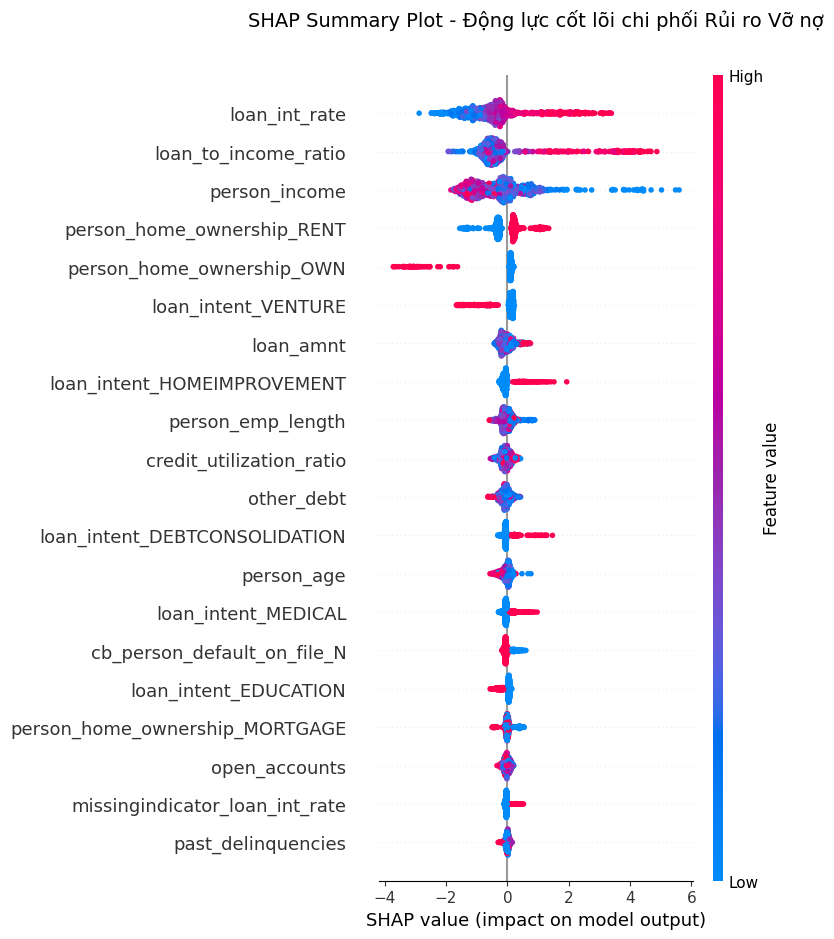

In [11]:
# Chuyển đổi dữ liệu Test nguyên thủy qua các tầng Preprocessor để SHAP tính toán
X_test_transformed = best_model.named_steps["preprocessor"].transform(X_test)

# Trích xuất hệ thống Tên biến sau mã hóa (One-hot & Missing Indicators)
numeric_out = best_model.named_steps["preprocessor"].named_transformers_["num"].named_steps["imputer"].get_feature_names_out(numerical_features)
cat_out = best_model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(categorical_features)
feature_names_out = np.concatenate([numeric_out, cat_out])

# Trích xuất mô hình lõi (XGBoost Classifier) và khởi tạo SHAP Explainer
xgb_core_model = best_model.named_steps["model"]
explainer = shap.TreeExplainer(xgb_core_model)

# Giới hạn kích thước sample để chạy hình ảnh mượt mà (vd: lấy 1000 dòng ngẫu nhiên từ Test)
X_test_sample = X_test_transformed[:1000]
shap_values = explainer.shap_values(X_test_sample)

# Vẽ biểu đồ tổng quan đánh giá sự tác động
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary Plot - Động lực cốt lõi chi phối Rủi ro Vỡ nợ", fontsize=14, y=1.05)
shap.summary_plot(shap_values, X_test_sample, feature_names=feature_names_out, show=False)
plt.tight_layout()
plt.show()

# Một vài minh hoạ trực quan bổ sung

Biểu đồ phân phối biến mục tiêu (Tỷ lệ mất cân bằng dữ liệu)

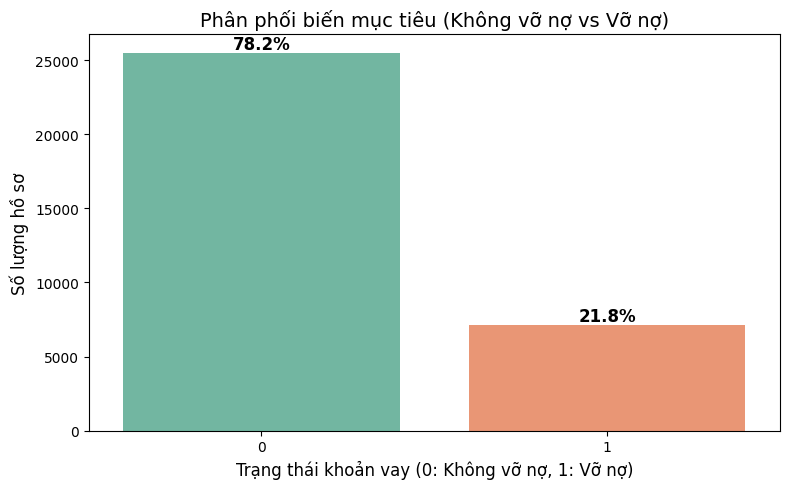

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Giả sử biến mục tiêu của bạn tên là 'loan_status' trong dataframe 'df'
# Thay 'loan_status' bằng tên cột nhãn thực tế của bạn
target_col = 'loan_status' 

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x=target_col, palette='Set2')
plt.title('Phân phối biến mục tiêu (Không vỡ nợ vs Vỡ nợ)', fontsize=14)
plt.xlabel('Trạng thái khoản vay (0: Không vỡ nợ, 1: Vỡ nợ)', fontsize=12)
plt.ylabel('Số lượng hồ sơ', fontsize=12)

# Thêm % lên từng cột
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

Boxplot so sánh Trước/Sau khi Winsorizing (Xử lý Outlier)

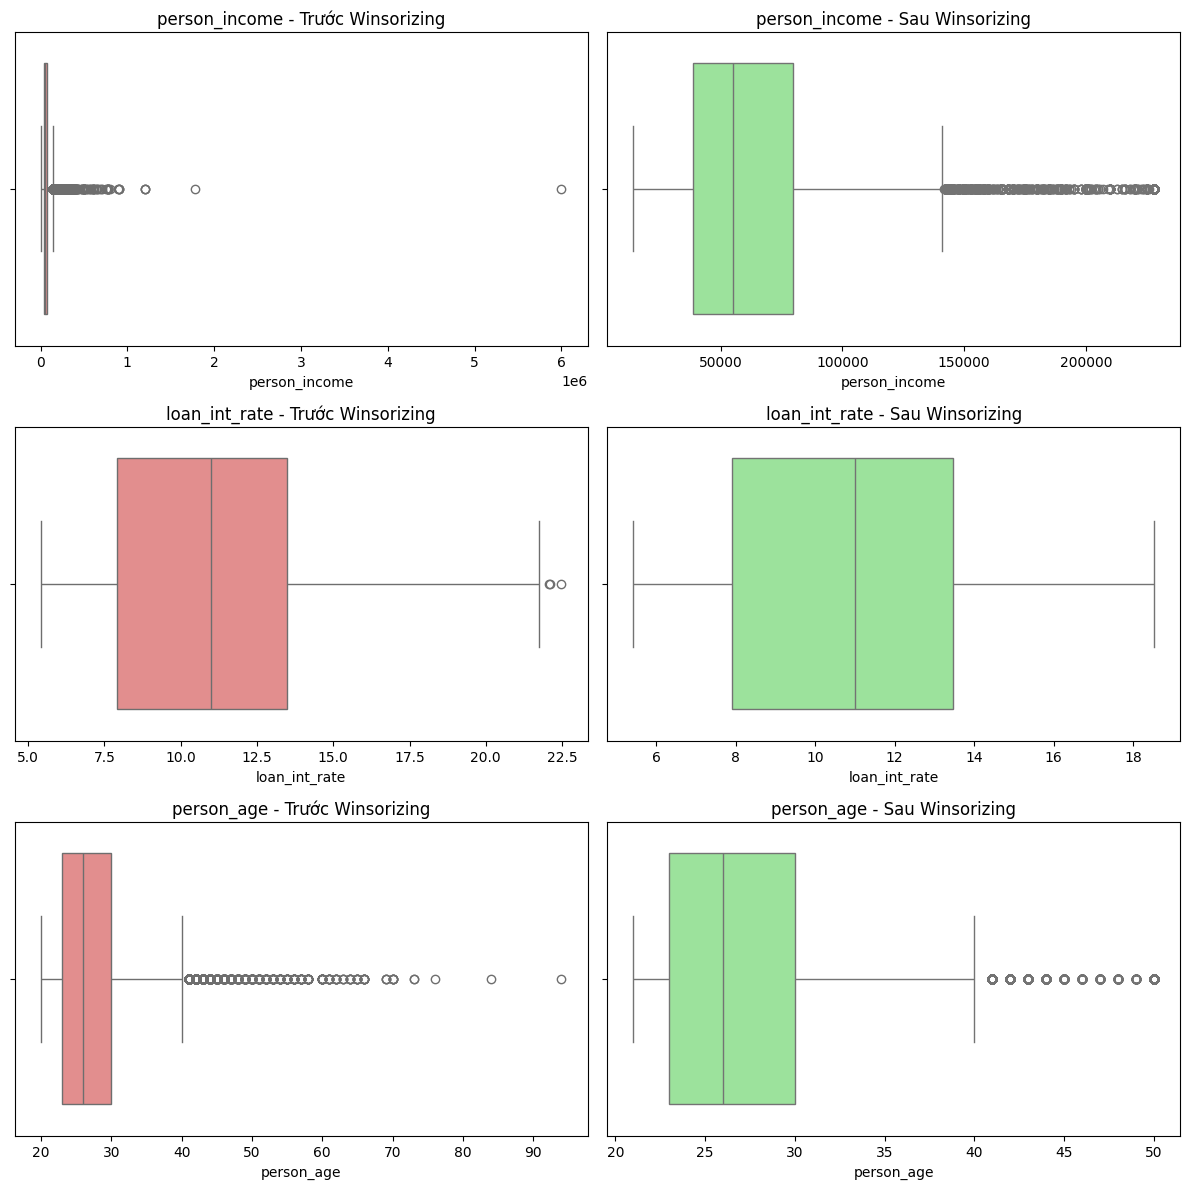

In [14]:
# Chọn ra 3 biến quan trọng để minh họa
features_to_plot = ['person_income', 'loan_int_rate', 'person_age'] # Đổi tên cột cho khớp
fig, axes = plt.subplots(len(features_to_plot), 2, figsize=(12, 4 * len(features_to_plot)))

# 1. Dữ liệu TRƯỚC khi Winsorize (Chỉ lấy các biến số liên tục)
df_before_winsor = X_train[numerical_features].copy()

# 2. Trích xuất công cụ Winsorizer đã được huấn luyện từ mô hình tốt nhất
fitted_winsorizer = best_model.named_steps["preprocessor"].named_transformers_["num"].named_steps["winsorizer"]

# 3. Áp dụng biến đổi và chuyển đổi lại thành định dạng Pandas DataFrame
X_winsorized_array = fitted_winsorizer.transform(df_before_winsor)
df_after_winsor = pd.DataFrame(
    X_winsorized_array, 
    columns=numerical_features, 
    index=df_before_winsor.index # Giữ nguyên index để dễ đối chiếu
)

for i, col in enumerate(features_to_plot):
    # Trước khi Winsorizing
    sns.boxplot(data=df_before_winsor, x=col, ax=axes[i, 0], color='lightcoral')
    axes[i, 0].set_title(f'{col} - Trước Winsorizing')
    
    # Sau khi Winsorizing
    sns.boxplot(data=df_after_winsor, x=col, ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'{col} - Sau Winsorizing')

plt.tight_layout()
plt.show()

Heatmap Ma trận tương quan

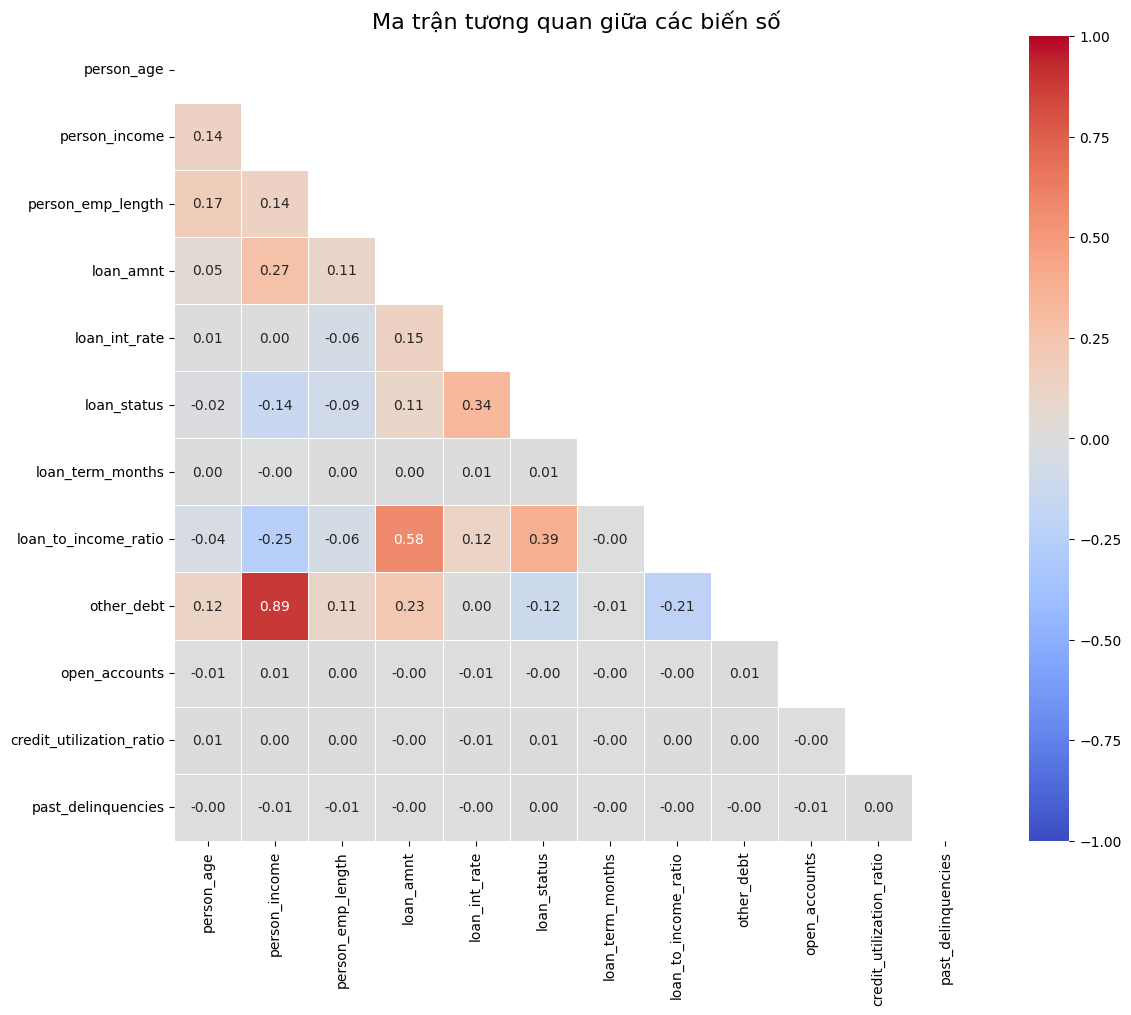

In [15]:
import numpy as np

# Lấy các cột numeric
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(12, 10))
corr_matrix = numeric_df.corr()

# Dùng mask để ẩn nửa trên của ma trận (vì nó đối xứng, giúp dễ nhìn hơn)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
            vmax=1, vmin=-1, center=0, square=True, linewidths=.5)

plt.title('Ma trận tương quan giữa các biến số', fontsize=16)
plt.tight_layout()
plt.show()

ROC Curve (Train vs Test)

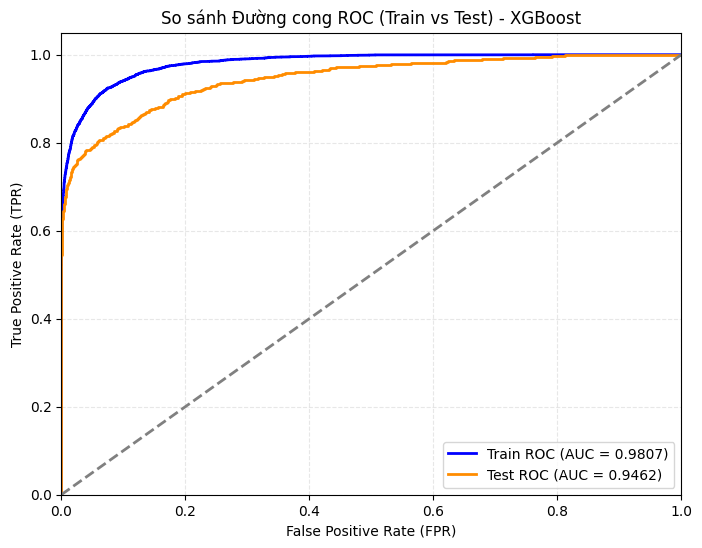

In [17]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# 1. Lấy xác suất dự báo lớp 1 (Vỡ nợ) từ mô hình tốt nhất cho tập Train và Test
y_prob_train = best_model.predict_proba(X_train)[:, 1]
# Biến y_prob_test đã được khai báo sẵn ở Cell 9, nhưng có thể gọi lại cho chắc chắn
y_prob_test = best_model.predict_proba(X_test)[:, 1]

# 2. Tính FPR, TPR và Thresholds cho tập Train
fpr_train, tpr_train, _ = roc_curve(y_train, y_prob_train)
roc_auc_train = auc(fpr_train, tpr_train)

# 3. Tính FPR, TPR và Thresholds cho tập Test
fpr_test, tpr_test, _ = roc_curve(y_test, y_prob_test)
roc_auc_test = auc(fpr_test, tpr_test)

# 4. Vẽ biểu đồ ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, color='blue', lw=2, label=f'Train ROC (AUC = {roc_auc_train:.4f})')
plt.plot(fpr_test, tpr_test, color='darkorange', lw=2, label=f'Test ROC (AUC = {roc_auc_test:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--') # Đường random guess

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('So sánh Đường cong ROC (Train vs Test) - XGBoost')
plt.legend(loc="lower right")
plt.grid(alpha=0.3, linestyle='--')
plt.show()

Precision-Recall Curve kèm điểm Cut-off 0.404

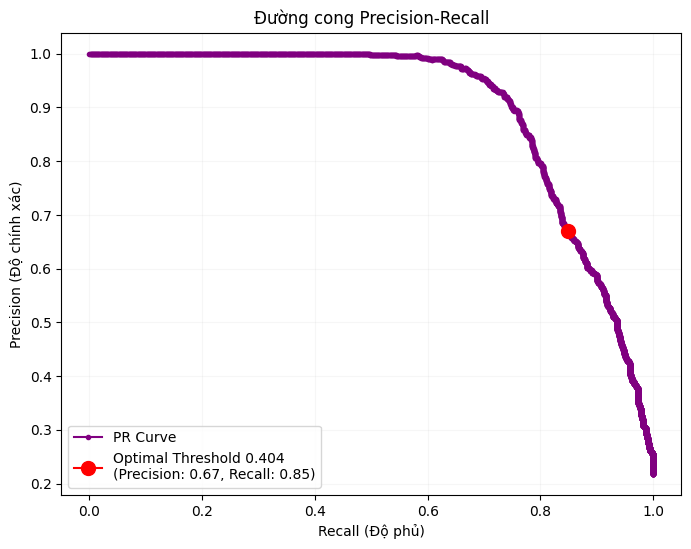

In [21]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob_test)

# Tìm index của threshold gần với 0.404 nhất
optimal_idx = np.argmin(np.abs(thresholds - 0.404))
opt_precision = precisions[optimal_idx]
opt_recall = recalls[optimal_idx]

plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, marker='.', label='PR Curve', color='purple')
plt.plot(opt_recall, opt_precision, marker='o', markersize=10, color='red', 
         label=f'Optimal Threshold 0.404\n(Precision: {opt_precision:.2f}, Recall: {opt_recall:.2f})')

plt.xlabel('Recall (Độ phủ)')
plt.ylabel('Precision (Độ chính xác)')
plt.title('Đường cong Precision-Recall')
plt.legend(loc="lower left")
plt.grid(alpha=0.1)
plt.show()

Confusion Matrix (Dạng Heatmap) tại ngưỡng 0.404

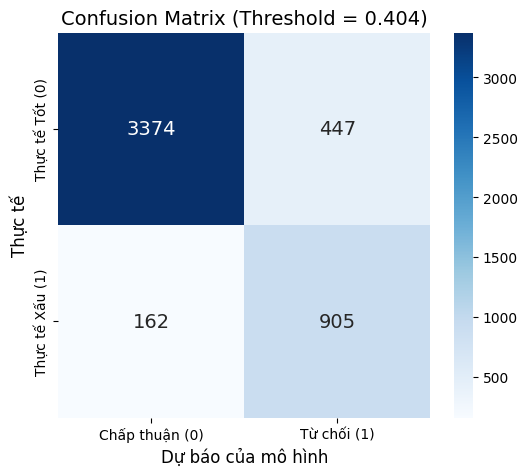

In [22]:
from sklearn.metrics import confusion_matrix

# Chuyển đổi xác suất thành nhãn phân loại dựa trên ngưỡng 0.404
custom_threshold = 0.404
y_pred_custom = (y_prob_test >= custom_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred_custom)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Chấp thuận (0)', 'Từ chối (1)'], 
            yticklabels=['Thực tế Tốt (0)', 'Thực tế Xấu (1)'], annot_kws={"size": 14})

plt.title('Confusion Matrix (Threshold = 0.404)', fontsize=14)
plt.xlabel('Dự báo của mô hình', fontsize=12)
plt.ylabel('Thực tế', fontsize=12)
plt.show()

Biểu đồ Cost vs Threshold

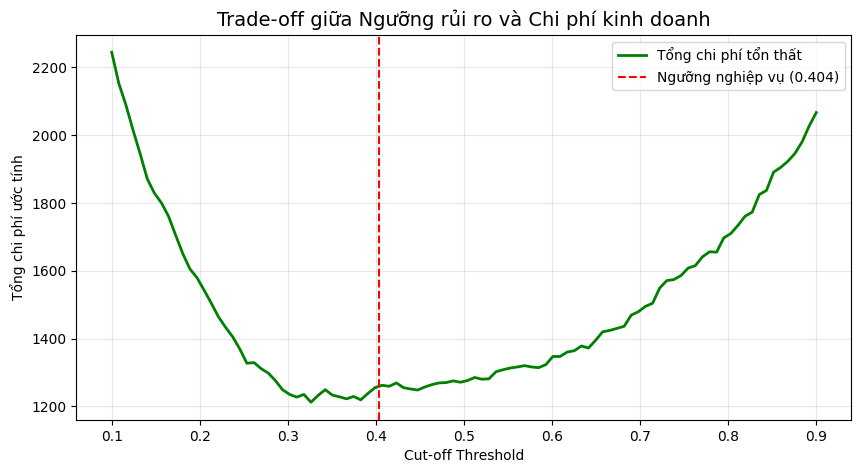

In [24]:
import numpy as np

# Giả định ma trận chi phí của bạn (ví dụ: FP cost = 1, FN cost = 5)
cost_FP = 1  # Từ chối oan người tốt (Mất lãi suất)
cost_FN = 5  # Nhận nhầm người xấu (Mất vốn)

costs = []
thresholds_list = np.linspace(0.1, 0.9, 100)

for t in thresholds_list:
    y_pred_t = (y_prob_test >= t).astype(int)
    cm_t = confusion_matrix(y_test, y_pred_t)
    # cm_t[0,1] là False Positive, cm_t[1,0] là False Negative
    FP = cm_t[0, 1]
    FN = cm_t[1, 0]
    total_cost = (FP * cost_FP) + (FN * cost_FN)
    costs.append(total_cost)

# Tìm chi phí thấp nhất
min_cost_idx = np.argmin(costs)
opt_thresh_cost = thresholds_list[min_cost_idx]

plt.figure(figsize=(10, 5))
plt.plot(thresholds_list, costs, color='green', linewidth=2, label='Tổng chi phí tổn thất')
plt.axvline(x=0.404, color='red', linestyle='--', label='Ngưỡng nghiệp vụ (0.404)')
# plt.axvline(x=0.670, color='orange', linestyle='--', label='Ngưỡng cũ (0.670)')

plt.xlabel('Cut-off Threshold')
plt.ylabel('Tổng chi phí ước tính')
plt.title('Trade-off giữa Ngưỡng rủi ro và Chi phí kinh doanh', fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()